        # How does each rule score on the thirteen weeks it never saw, and which way is each wrong?

        **Week 4, Friday, chapter 2 of 3.** **The ticket.** Flipkart, the Lucknow fulfilment centre, festive packer headcount. The centre
has 104 weeks of outbound shipments, the weeks beginning Monday 30 September 2024 to Monday 21
September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025, and falls on
Sunday 8 November 2026. A packer packs about 120 shipments a shift. The planner must book packer
shifts for the eight festive weeks beginning 12 October to 30 November 2026. A vendor's demand
model promises the festive window 22 percent above last year's; finance's rule is last year's
window plus 4 percent, eighteen points apart. An idle packer-shift costs Rs 650 (assumed, Rs 500 to
800) and a late shipment Rs 25 (assumed, Rs 15 to 40). Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

        Chapter 1 found the peak two weeks before Diwali's week and showed that a copy of the same
        calendar week lands it a week late in 2025 and two weeks early in 2026. This notebook scores
        every rule, and the vendor's curve, on weeks none of them saw.

        **Who needs the answer.** The FC planner, who may send only a forecast that has beaten the
        house rule on weeks it never saw, and the regional operations head, who must say yes or no
        to the vendor's plus 22 percent before a shift is booked.

        **The questions on the way.** Which weeks do we hide, and from which week do we forecast?
        What does each rule forecast for them? Which rule scores best? What did the vendor score,
        and what does its fit to the past say? Which way is each rule wrong, and what does that
        cost in rupees? Does the score match the printed error table?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
y = weekly.set_index("week_start").shipments
train, hold = y.iloc[:91], y.iloc[91:]
print(f"training weeks: {len(train)}, {train.index[0].date()} to {train.index[-1].date()}")
print(f"hold-out weeks: {len(hold)}, {hold.index[0].date()} to {hold.index[-1].date()}")
print(vendor.kind.value_counts().to_string())
check("91 training weeks and 13 hidden ones", (len(train), len(hold)) == (91, 13))
check("the vendor's hold-out rows are forecasts, never fits",
      set(vendor.set_index("week_start").loc[hold.index, "kind"]) == {"holdout"})

training weeks: 91, 2024-09-30 to 2026-06-22
hold-out weeks: 13, 2026-06-29 to 2026-09-21
kind
fitted      91
holdout     13
forecast    10
PASS 91 training weeks and 13 hidden ones
PASS the vendor's hold-out rows are forecasts, never fits


## Which weeks do we hide, and how is the score counted?

The plan covers eight weeks ahead, so the test hides at least as many: the last thirteen
weeks, 29 June to 21 September 2026. Every rule forecasts all thirteen from one week, the
week of 22 June 2026, as a planner standing there would have. The score is the **mean
absolute error** (MAE): each week's miss in shipments, sign dropped, averaged. Three hidden
weeks with misses of 10, 5 and 10 (invented) score 8.3.

In [2]:
misses = [10, -5, 10]                          # three hidden weeks' misses (invented)
mae_toy = sum(abs(m) for m in misses) / len(misses)
print(f"MAE: {mae_toy:.1f}")
check("the toy MAE is 8.3", round(mae_toy, 1) == 8.3)

MAE: 8.3
PASS the toy MAE is 8.3


## What does each rule forecast for the hidden weeks?

Each rule in one line, all from the week of 22 June 2026. **Naive** repeats that week.
**Drift** draws the straight line from the first week through that week and extends it.
**The house bot** copies the week 52 weeks back (same week last year). **Finance's rule**
is the house bot plus 4 percent. **Festival-aligned** copies the week at the same distance
from last year's Diwali for the weeks from five before Diwali to four after, the same
calendar week otherwise, and adds the 4 percent a year the centre grew. No hidden week lies
within five weeks of a Diwali, so on these weeks festival-aligned and finance's rule are
one rule.

In [3]:
origin = train.index[-1]
h = pd.Series(range(1, 14), index=hold.index)
slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
growth = y.iloc[52:91].sum() / y.iloc[0:39].sum() - 1
last_year = y.shift(52).loc[hold.index]
rules = pd.DataFrame({
    "naive": train.iloc[-1],
    "drift": (train.iloc[-1] + h * slope).round(),
    "house bot": last_year,
    "finance": (last_year * 1.04).round(),
    "festival-aligned": (last_year * 1.04).round(),
}).astype(int)
nearest = min(abs((d - pd.Timestamp("2026-11-02")).days) // 7 for d in hold.index)
print(f"origin {origin.date()}, drift {slope:.0f} a week, growth a year {growth:.1%}")
print(f"the hidden week nearest Diwali 2026 is {nearest} weeks before it")
print(rules.head(3).to_string())
check("the growth the training weeks show rounds to 4 percent", round(growth, 2) == 0.04)
check("no hidden week lies within five weeks of a Diwali", nearest > 5)

origin 2026-06-22, drift 70 a week, growth a year 4.0%
the hidden week nearest Diwali 2026 is 6 weeks before it
             naive   drift  house bot  finance  festival-aligned
week_start                                                      
2026-06-29  218300  218370     198800   206752            206752
2026-07-06  218300  218440     192400   200096            200096
2026-07-13  218300  218510     194200   201968            201968
PASS the growth the training weeks show rounds to 4 percent
PASS no hidden week lies within five weeks of a Diwali


**Predict before you run.** Which rule has the lowest MAE on the thirteen hidden weeks?

a) naive
b) drift
c) the house bot
d) festival-aligned, tied with finance's rule

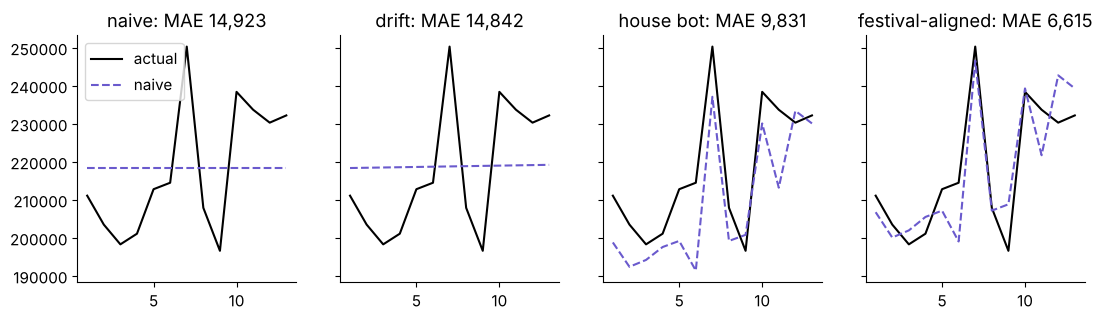

finance              6615
festival-aligned     6615
house bot            9831
drift               14842
naive               14923
PASS festival-aligned and finance tie
PASS the house bot beats naive and drift


In [4]:
def mae(f):
    return (f - hold).abs().mean()

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, name in zip(axes, ["naive", "drift", "house bot", "festival-aligned"]):
    ax.plot(range(1, 14), hold.values, color="black", label="actual")
    ax.plot(range(1, 14), rules[name].values, ls="--", color="slateblue", label=name)
    ax.set_title(f"{name}: MAE {mae(rules[name]):,.0f}")
axes[0].legend()
plt.show()
scores = rules.apply(mae).round().astype(int).sort_values()
print(scores.to_string())
check("festival-aligned and finance tie", scores["festival-aligned"] == scores["finance"])
check("the house bot beats naive and drift", scores["house bot"] < min(scores["naive"], scores["drift"]))

**What happened.** The answer is d. Festival-aligned and finance's rule tie at 6,615
shipments a week, the house bot scores 9,831, and naive and drift miss by 14,923 and 14,842. The bot
beats naive because it carries the August sale and the summer dip from last year; it loses
to the 4 percent rules because a growing series makes last year's week too low. The tie is
honest: on weeks this far from Diwali the two rules are the same arithmetic.

**Your turn.** Score the vendor on the same hidden weeks. Type these lines into the empty
cell below and run it:

```python
v = vendor.set_index("week_start").vendor_shipments
print(f"vendor MAE: {mae(v.loc[hold.index]):,.0f}")
```

## What does the vendor's fit to the past say about its forecast?

**The plausible wrong answer.** "The vendor's curve sits within 2 percent of every week of
history, so its plus 22 percent can be trusted." A fit is drawn through weeks the model has
seen; a forecast is made for weeks it has not.

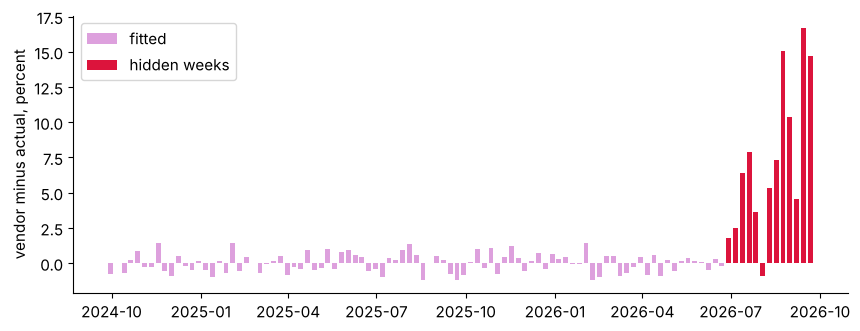

largest miss on the 91 fitted weeks: 1.4%
vendor MAE on the hidden weeks: 16,400
PASS the fit stays within 2 percent
PASS the vendor's MAE is at least 30 percent above festival-aligned


In [5]:
v = vendor.set_index("week_start").vendor_shipments
fit_gap = ((v.loc[train.index] - train) / train).abs().max()
hold_gap = (v.loc[hold.index] - hold) / hold
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(train.index, (v.loc[train.index] - train) / train * 100, width=5, color="plum", label="fitted")
ax.bar(hold.index, hold_gap * 100, width=5, color="crimson", label="hidden weeks")
ax.set_ylabel("vendor minus actual, percent")
ax.legend()
plt.show()
print(f"largest miss on the 91 fitted weeks: {fit_gap:.1%}")
print(f"vendor MAE on the hidden weeks: {mae(v.loc[hold.index]):,.0f}")
check("the fit stays within 2 percent", fit_gap <= 0.02)
check("the vendor's MAE is at least 30 percent above festival-aligned",
      mae(v.loc[hold.index]) >= 1.3 * scores["festival-aligned"])

**Why it is wrong.** The vendor never misses its fitted weeks by more than 1.4 percent, and
it misses the hidden weeks by 16,400 a week, 148 percent worse than festival-aligned and 67
percent worse than the house bot. The check is the one the room fixed before scoring:
error on the weeks it never saw. The fix is to send nothing to the plan that loses to the
house bot there.

## Which way is each rule wrong, and what does each direction cost?

**Predict before you run.** Which rule's misses cost the least once a late shipment costs
Rs 25 and an idle packer-shift Rs 650, about Rs 5.42 a shipment?

a) festival-aligned, since its MAE is lowest
b) the vendor
c) the house bot
d) naive

                    MAE  weeks too high  idle Rs lakh  late Rs lakh  cost Rs lakh
vendor            16400              12          11.4           0.5          11.9
finance            6615               6           2.2          11.3          13.5
festival-aligned   6615               6           2.2          11.3          13.5
drift             14842               8           5.6          22.4          28.0
naive             14923               8           5.4          23.4          28.8
house bot          9831               2           0.4          30.1          30.5


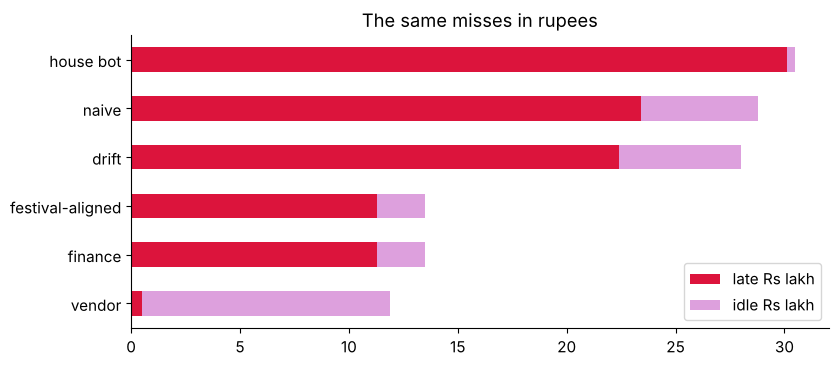

PASS the vendor errs high on 12 of 13 weeks
PASS priced, the vendor costs less than festival-aligned


In [6]:
rules["vendor"] = v.loc[hold.index]
over = rules.sub(hold, axis=0).clip(lower=0).sum()
under = rules.rsub(hold, axis=0).clip(lower=0).sum()
priced = pd.DataFrame({
    "MAE": rules.apply(mae).round().astype(int),
    "weeks too high": rules.gt(hold, axis=0).sum(),
    "idle Rs lakh": (over * 650 / 120 / 1e5).round(1),
    "late Rs lakh": (under * 25 / 1e5).round(1),
})
priced["cost Rs lakh"] = (over * 650 / 120 / 1e5 + under * 25 / 1e5).round(1)
print(priced.sort_values("cost Rs lakh").to_string())
priced[["late Rs lakh", "idle Rs lakh"]].sort_values("late Rs lakh").plot.barh(stacked=True,
    color=["crimson", "plum"], title="The same misses in rupees")
plt.show()
check("the vendor errs high on 12 of 13 weeks", priced.loc["vendor", "weeks too high"] == 12)
check("priced, the vendor costs less than festival-aligned",
      priced.loc["vendor", "cost Rs lakh"] < priced.loc["festival-aligned", "cost Rs lakh"])

**What happened.** The answer is b, and it is the uncomfortable result. The vendor's
misses cost Rs 11.9 lakh, festival-aligned's Rs 13.5 lakh, the house bot's Rs 30.5 lakh.
The vendor errs high on 12 of 13 weeks, and a shipment of spare capacity costs Rs 5.42
against Rs 25 for a late one, so its bigger misses are the cheaper kind. The bot's misses
are the dear kind: 11 of its 13 weeks are too low, which is why it costs more than naive
while scoring a lower MAE.

This says that erring high pays at these costs. It does not say the vendor should carry
the plan: its high bias was never sized, it grows with the weeks ahead (3.6 percent in the
first six weeks, 11.5 percent in the last six), and no hidden week holds a festival, where
the vendor copies the wrong weeks. Chapter 3 raises the festival-aligned forecast by a sized
amount instead.

## Does the score match the printed error table?

A second route to the same number: print festival-aligned's thirteen misses as a table and
average them by hand.

In [7]:
table = pd.DataFrame({"actual": hold, "festival-aligned": rules["festival-aligned"]})
table["miss"] = table["festival-aligned"] - table["actual"]
print(table.to_string())
by_hand = sum(abs(m) for m in table["miss"]) / 13
print(f"MAE from the printed misses: {by_hand:,.0f}")
check("the printed table gives the same MAE", round(by_hand) == scores["festival-aligned"])

            actual  festival-aligned   miss
week_start                                 
2026-06-29  211100            206752  -4348
2026-07-06  203500            200096  -3404
2026-07-13  198300            201968   3668
2026-07-20  201100            205504   4404
2026-07-27  212800            207168  -5632
2026-08-03  214500            199056 -15444
2026-08-10  250300            246584  -3716
2026-08-17  207900            207168   -732
2026-08-24  196600            208832  12232
2026-08-31  238400            239304    904
2026-09-07  233700            221728 -11972
2026-09-14  230300            242736  12436
2026-09-21  232200            239304   7104
MAE from the printed misses: 6,615
PASS the printed table gives the same MAE


## How would you answer "how do you evaluate a forecast?" in an interview?

Hold out the latest weeks, at least as many as the plan's horizon, and forecast them from
one origin. Fix the error measure before anyone scores, in the business's unit: shipments,
then rupees. Compare every candidate with the naive and the seasonal copy, and send nothing
that loses to them. Report which way the misses run, because a late shipment and an idle
shift cost different amounts. The trap the interviewer fishes for is judging by the fit.

## What did chapter 2 answer?

- **Which weeks are hidden?** The last thirteen, 29 June to 21 September 2026, forecast
  from the week of 22 June 2026.
- **Which rule scores best?** Festival-aligned and finance's rule, tied at 6,615 a week;
  the house bot 9,831; naive 14,923; drift 14,842.
- **What did the vendor score?** 16,400, after fitting history within 1.4 percent: fit is
  not forecast.
- **Which way is each wrong, and at what cost?** The vendor errs high on 12 of 13 weeks and
  costs Rs 11.9 lakh; festival-aligned Rs 13.5 lakh; the bot errs low and costs Rs 30.5
  lakh.
- **Does the table agree?** Yes, 6,615 from the printed misses.

Chapter 3 asks what the hold-out cannot: where the festival falls this year, and how far
above the forecast the plan should sit.